# Regression Models in `scikitlearn`

**OBJECTIVES**

- Use `LinearRegression` to build regression models
- Interpret a fit regression models parameters
- Understand the train/test split process
- Use `StandardScaler` to scale features
- Use `OneHotEncoder` to encode categorical features
- Use `Pipeline` to combine transformers and estimators

### The Initial Problem

Below, the dataset from Geron's [Hands on Machine Learning with `scikitlearn` and `pytorch`]() Chapter 2 is loaded.  This dataset represents neighborhoods in California and the task is to predict `median_house_value`. 

In [2]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [3]:
housing = pd.read_csv('data/housing.csv')

In [4]:
housing.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [5]:
housing.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB


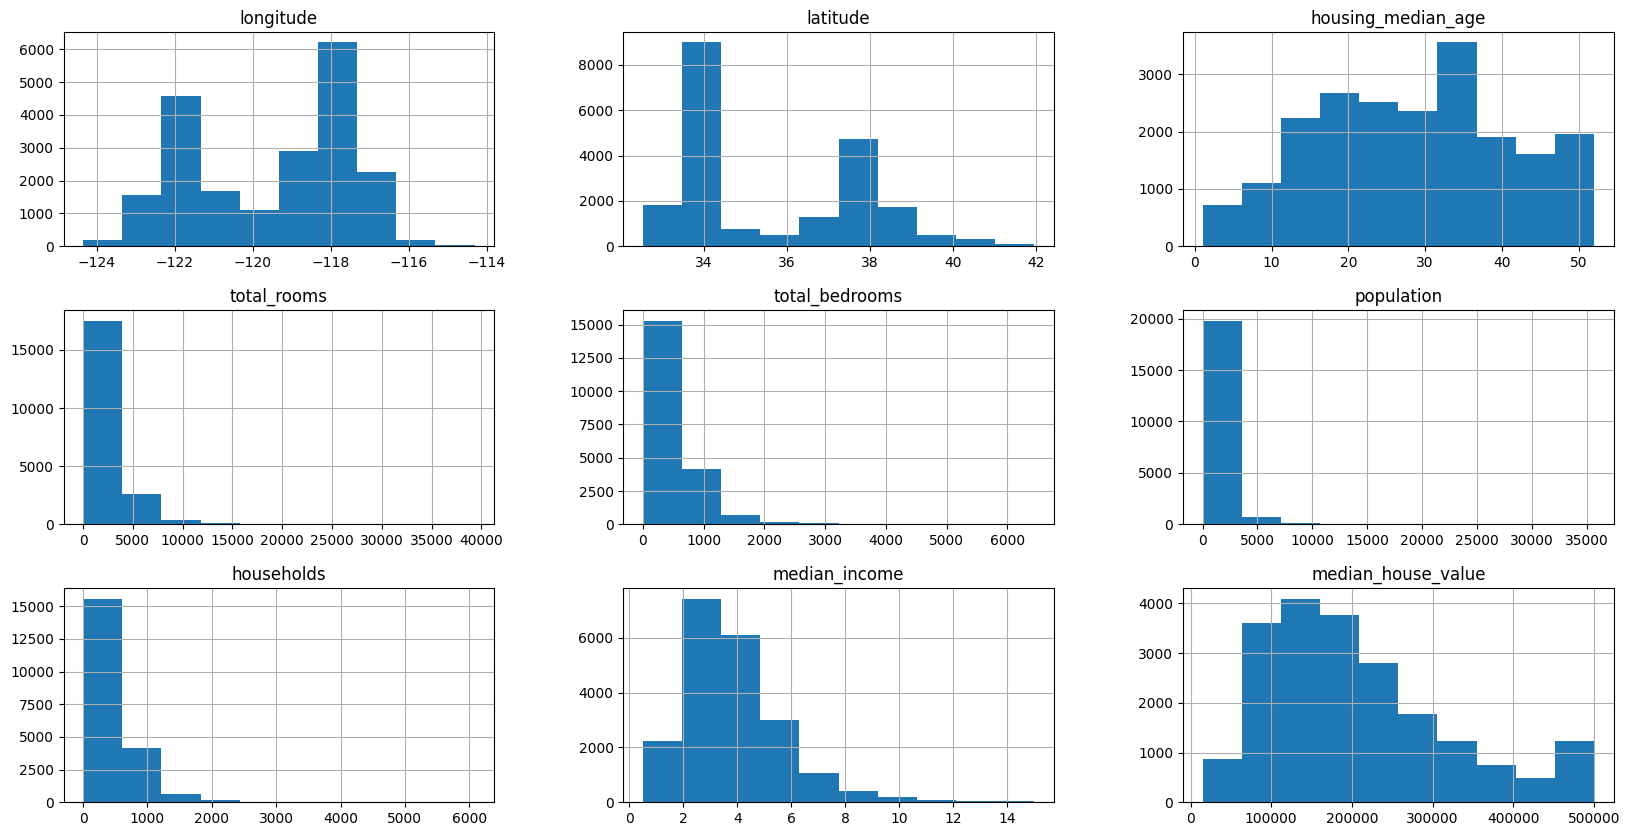

In [6]:
housing.hist(figsize = (20, 10));

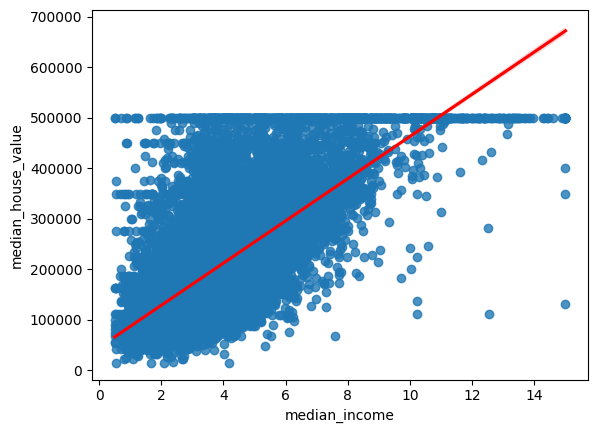

In [7]:
sns.regplot(data = housing, x = 'median_income', y = 'median_house_value', line_kws = {'color': 'red'});

### Regression with `sklearn`

- Create `X` and `y` -- **X MUST BE 2D**
- Instantiate
- Fit
- Predict/Evaluate

In [8]:
from sklearn.linear_model import LinearRegression

In [9]:
X = housing[['median_income']]
y = housing['median_house_value']

In [10]:
#instantiate
lr = LinearRegression()

In [11]:
#fit
lr.fit(X, y)

LinearRegression()

In [12]:
#predict
lr.predict(X)

array([393027.73007889, 392033.03646789, 348400.25790111, ...,
       116135.12034649, 123123.05193305, 144914.36490692])

In [13]:
params = {'slope': lr.coef_[0], 
 'intercept': lr.intercept_}

In [14]:
pd.DataFrame(params, index = ['median_income_model'])

,slope,intercept
median_income_model,41793.849202,45085.576703


### Evaluation Metrics

- Built in $r^2$: $$r^2 = 1 - \frac{RSS}{TSS}$$
- `mean_squared_error`: built in in `sklearn.metrics`
- **RMSE**: root mean squared error -- square root of `mean_squared_error`

In [15]:
#r^2 from scratch
rss = np.sum((lr.predict(X) - y)**2)
tss = np.sum((y - y.mean())**2)

In [16]:
1 - rss/tss

0.47344749180719903

In [17]:
lr.score(X, y)

0.47344749180719903

In [18]:
from sklearn.metrics import mean_squared_error

In [19]:
#MSE
mean_squared_error(y, lr.predict(X))

7011311502.929527

In [20]:
#RMSE
np.sqrt(mean_squared_error(y, lr.predict(X)))

83733.57452616918

In [22]:
housing.head(2)

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY


### Engineering Features

Next, we will consider more features, encode categorical features, and engineer new features from existing. Specifically we will:

- Engineer new features from the ratios rooms per house, bedrooms per rooms, and people per house
- Create an `income_cat` feature that bins the median_income column
- Use `OneHotEncoder` on the `ocean_proximity` feature to make it numeric
  

In [36]:
housing["rooms_per_house"] = housing["total_rooms"] / housing["households"]
housing["bedrooms_ratio"] = housing["total_bedrooms"] / housing["total_rooms"]
housing["people_per_house"] = housing["population"] / housing["households"]

In [29]:
housing["income_cat"] = pd.cut(housing["median_income"],
                               bins=[0., 1.5, 3.0, 4.5, 6., np.inf],
                               labels=[1, 2, 3, 4, 5])

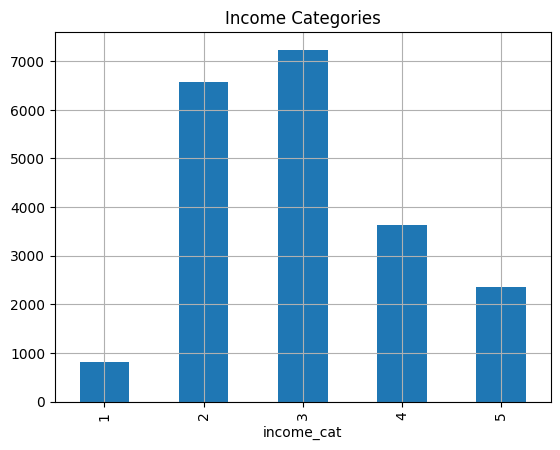

In [31]:
housing['income_cat'].value_counts().sort_index().plot(kind = 'bar')
plt.title('Income Categories')
plt.grid();

In [33]:
from sklearn.compose import make_column_transformer
from sklearn.preprocessing import OneHotEncoder

In [65]:
transformer = make_column_transformer((OneHotEncoder(drop = 'first'), ['ocean_proximity']),
                                      remainder = 'passthrough',
                                     verbose_feature_names_out=False)

In [66]:
housing.head(2)

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity,income_cat,rooms_per_house,bedrooms_ratio,people_per_house
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY,5,6.984127,0.146591,2.555556
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY,5,6.238137,0.155797,2.109842


### Selecting features

A basic approach to selecting features is to explore **correlations** with the target feature.  

In [67]:
housing.select_dtypes(['float', 'int', 'category']).corr()[['median_house_value']].sort_values(by = 'median_house_value')

,median_house_value
bedrooms_ratio,-0.255880
latitude,-0.144160
longitude,-0.045967
population,-0.024650
people_per_house,-0.023737
total_bedrooms,0.049686
households,0.065843
housing_median_age,0.105623
total_rooms,0.134153
rooms_per_house,0.151948


In [68]:
housing.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 14 columns):
 #   Column              Non-Null Count  Dtype   
---  ------              --------------  -----   
 0   longitude           20640 non-null  float64 
 1   latitude            20640 non-null  float64 
 2   housing_median_age  20640 non-null  float64 
 3   total_rooms         20640 non-null  float64 
 4   total_bedrooms      20433 non-null  float64 
 5   population          20640 non-null  float64 
 6   households          20640 non-null  float64 
 7   median_income       20640 non-null  float64 
 8   median_house_value  20640 non-null  float64 
 9   ocean_proximity     20640 non-null  object  
 10  income_cat          20640 non-null  category
 11  rooms_per_house     20640 non-null  float64 
 12  bedrooms_ratio      20433 non-null  float64 
 13  people_per_house    20640 non-null  float64 
dtypes: category(1), float64(12), object(1)
memory usage: 2.1+ MB


In [69]:
housing_nona = housing.dropna()

In [70]:
housing_nona.info()

<class 'pandas.core.frame.DataFrame'>
Index: 20433 entries, 0 to 20639
Data columns (total 14 columns):
 #   Column              Non-Null Count  Dtype   
---  ------              --------------  -----   
 0   longitude           20433 non-null  float64 
 1   latitude            20433 non-null  float64 
 2   housing_median_age  20433 non-null  float64 
 3   total_rooms         20433 non-null  float64 
 4   total_bedrooms      20433 non-null  float64 
 5   population          20433 non-null  float64 
 6   households          20433 non-null  float64 
 7   median_income       20433 non-null  float64 
 8   median_house_value  20433 non-null  float64 
 9   ocean_proximity     20433 non-null  object  
 10  income_cat          20433 non-null  category
 11  rooms_per_house     20433 non-null  float64 
 12  bedrooms_ratio      20433 non-null  float64 
 13  people_per_house    20433 non-null  float64 
dtypes: category(1), float64(12), object(1)
memory usage: 2.2+ MB


### Building a multiple regression model

Now we will use all our features to build a regression model.

In [71]:
X = housing_nona.drop(columns = ['median_house_value', 'median_income'])
y = housing_nona['median_house_value']

In [72]:
from sklearn.pipeline import Pipeline

In [73]:
pipe = Pipeline([('ohe', transformer), ('model', LinearRegression())])

In [74]:
pipe.fit(X, y)

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/compose/_column_transformer.py:1623: FutureWarning: 
The format of the columns of the 'remainder' transformer in ColumnTransformer.transformers_ will change in version 1.7 to match the format of the other transformers.
At the moment the remainder columns are stored as indices (of type int). With the same ColumnTransformer configuration, in the future they will be stored as column names (of type str).
To use the new behavior now and suppress this warning, use ColumnTransformer(force_int_remainder_cols=False).

  warnings.warn(


Pipeline(steps=[('ohe',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('onehotencoder',
                                                  OneHotEncoder(drop='first'),
                                                  ['ocean_proximity'])],
                                   verbose_feature_names_out=False)),
                ('model', LinearRegression())])

In [75]:
pipe.score(X, y)

0.6006571221013801

### Explore the results

Now, we want to see what the features coefficients are and interpret them.

In [76]:
#feature names are in the ohe
pipe['ohe'].get_feature_names_out()

array(['ocean_proximity_INLAND', 'ocean_proximity_ISLAND',
       'ocean_proximity_NEAR BAY', 'ocean_proximity_NEAR OCEAN',
       'longitude', 'latitude', 'housing_median_age', 'total_rooms',
       'total_bedrooms', 'population', 'households', 'income_cat',
       'rooms_per_house', 'bedrooms_ratio', 'people_per_house'],
      dtype=object)

In [86]:
#make a list of coefficients from the model
#and intercept
coefs = list(pipe['model'].coef_) + [pipe['model'].intercept_]
#make a list of column names
columns = list(pipe['ohe'].get_feature_names_out()) + ['intercept']
#display things as a dataframe
coef_df = pd.DataFrame(np.array(coefs).T, index = columns, columns = ['coefs'])
coef_df

,coefs
ocean_proximity_INLAND,-3.725288e+04
ocean_proximity_ISLAND,1.529940e+05
ocean_proximity_NEAR BAY,-3.760406e+03
ocean_proximity_NEAR OCEAN,4.213167e+03
longitude,-2.968911e+04
latitude,-2.833520e+04
housing_median_age,1.151688e+03
total_rooms,6.863093e+00
total_bedrooms,-1.288449e+01
population,-4.242538e+01


### Comparing a different model

For now, we leave this as a black box -- the `RandomForestRegressor` is a different model available in `scikitlearn`.  Let's compare its performance to that of the regression model.

In [97]:
from sklearn.ensemble import RandomForestRegressor

In [98]:
forest_pipe = Pipeline([('ohe', transformer), ('model', RandomForestRegressor())])

In [99]:
forest_pipe.fit(X, y)

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/compose/_column_transformer.py:1623: FutureWarning: 
The format of the columns of the 'remainder' transformer in ColumnTransformer.transformers_ will change in version 1.7 to match the format of the other transformers.
At the moment the remainder columns are stored as indices (of type int). With the same ColumnTransformer configuration, in the future they will be stored as column names (of type str).
To use the new behavior now and suppress this warning, use ColumnTransformer(force_int_remainder_cols=False).

  warnings.warn(


Pipeline(steps=[('ohe',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('onehotencoder',
                                                  OneHotEncoder(drop='first'),
                                                  ['ocean_proximity'])],
                                   verbose_feature_names_out=False)),
                ('model', RandomForestRegressor())])

In [100]:
forest_pipe.score(X, y)

0.974217924000289

Hmmm, quite an improvement.  What could this mean?

In [87]:
errors = y - pipe.predict(X)

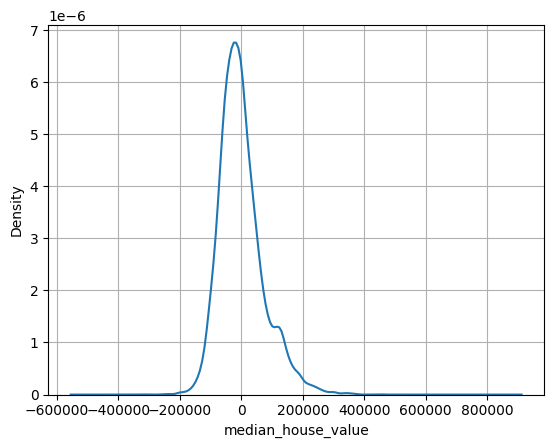

In [92]:
sns.kdeplot(errors)
plt.grid();

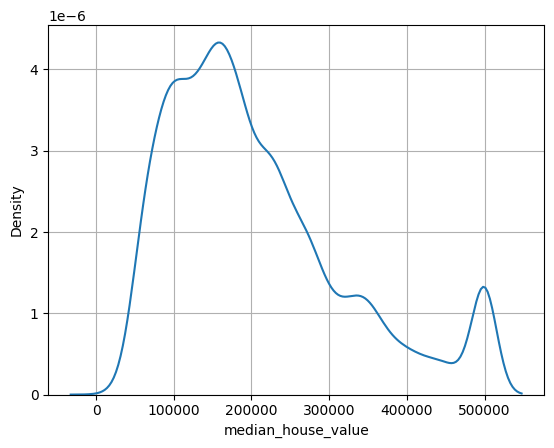

In [93]:
sns.kdeplot(y)
plt.grid();

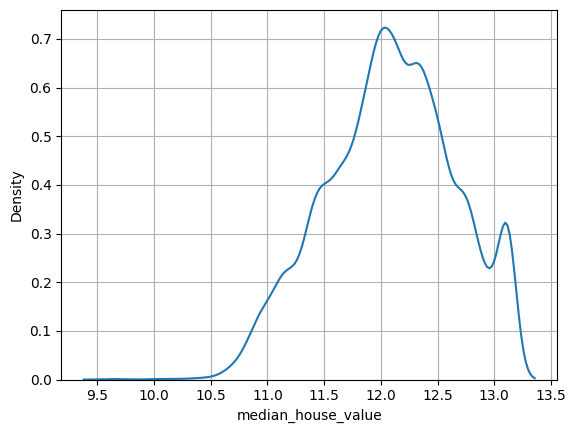

In [96]:
sns.kdeplot(np.log1p(y))
plt.grid();